In [ ]:
# Imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline   #Combines more than one step and runs them in one object, each step except the last must be a transformer and the last can be a model 
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer    #To fill Nan values with (mean, median, constant) value, thus helping avoiding Data leakage
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [ ]:
#Spliting training data and testing data
DATA_PATH = "../H2_Cleaned_classification.csv"
TARGET = "IsCanceled"

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=[TARGET])
y = df[TARGET]

categorical = X.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist() #Convert the non numerical columns into categorical
numeric = [c for c in X.columns if c not in categorical] #collect the rest of the columns (which are not categorical)

print(f"Total features: {X.shape[1]} ({len(numeric)} numeric, {len(categorical)} categorical)")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   #Making 5 folds 
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

Total features: 26 (17 numeric, 9 categorical)


In [ ]:
#Evaluation Helper and Dense preprocessing for PCA and LDA

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), numeric),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=0.005,
            sparse_output=False  # Dense output required for PCA and LDA
        )),
    ]), categorical),
])

results_log = []
fitted_models = {}

def evaluate_classifier(name, estimator, X_tr, y_tr, X_te, y_te, cv_splitter, plot_cm=True): # A function that trains, tests, and logs/record the output of the test
    cv_res = cross_validate(estimator, X_tr, y_tr, cv=cv_splitter, scoring=scoring, n_jobs=-1)
    
    estimator.fit(X_tr, y_tr)
    fitted_models[name] = estimator
    
    y_pred = estimator.predict(X_te)
    y_prob = estimator.predict_proba(X_te)[:, 1]
    
    train_acc = estimator.score(X_tr, y_tr)
    test_acc = accuracy_score(y_te, y_pred)
    
    row = { #What each row will log in the results_log array
        "Model": name,
        "CV Accuracy": f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}",
        "CV F1": f"{cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.4f}",
        "CV ROC-AUC": f"{cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}",
        "Train Acc": round(train_acc, 4),
        "Test Acc": round(test_acc, 4),
        "Test Precision": round(precision_score(y_te, y_pred), 4),
        "Test Recall": round(recall_score(y_te, y_pred), 4),
        "Test F1": round(f1_score(y_te, y_pred), 4),
        "Test ROC-AUC": round(roc_auc_score(y_te, y_prob), 4),
        "Test PR-AUC": round(average_precision_score(y_te, y_prob), 4),
    }
    results_log.append(row)
    
    print(f"=== {name} ===")
    print(f"Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
    print(classification_report(y_te, y_pred, target_names=["Not canceled", "Canceled"]))
    
    if plot_cm:
        cm = confusion_matrix(y_te, y_pred)
        fig, ax = plt.subplots(figsize=(4.5, 3.8))
        ConfusionMatrixDisplay(cm, display_labels=["Not canceled", "Canceled"]).plot(
            ax=ax, cmap="Blues", values_format="d"
        )
        ax.set_title(f"Confusion Matrix: {name}")
        plt.tight_layout()
        plt.show()
        
    return estimator

=== LR (Baseline) ===
Train Accuracy: 0.7687 | Test Accuracy: 0.7596
              precision    recall  f1-score   support

Not canceled       0.79      0.90      0.84      6929
    Canceled       0.64      0.41      0.50      2869

    accuracy                           0.76      9798
   macro avg       0.71      0.66      0.67      9798
weighted avg       0.74      0.76      0.74      9798



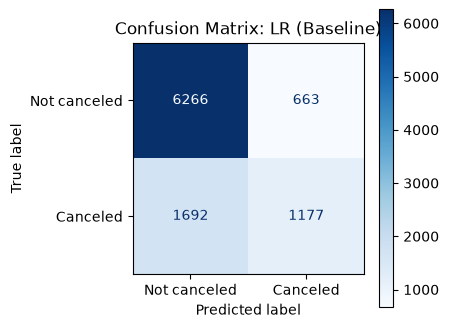

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['LeadTime','ArrivalDateYear','ArrivalDateMonth',...,'ADR', 'TotalOfSpecialRequests','HasCompany']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [4]:
#Baseline Model
model = Pipeline([
    ("prep", clone(preprocess)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

evaluate_classifier("LR (Baseline)", model, X_train, y_train, X_test, y_test, cv)

Best LR Params: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0.0, 'clf__solver': 'lbfgs'}
Best CV F1: 0.6077

=== LR (Tuned) ===
Train Accuracy: 0.7215 | Test Accuracy: 0.7163
              precision    recall  f1-score   support

Not canceled       0.86      0.71      0.78      6929
    Canceled       0.51      0.72      0.60      2869

    accuracy                           0.72      9798
   macro avg       0.69      0.72      0.69      9798
weighted avg       0.76      0.72      0.73      9798



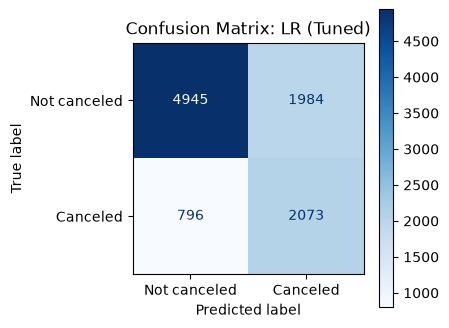

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['LeadTime','ArrivalDateYear','ArrivalDateMonth',...,'ADR', 'TotalOfSpecialRequests','HasCompany']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [ ]:
#Hyperparameter tuned model

lr_tune_pipe = Pipeline([
    ("prep", clone(preprocess)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])  #build a new unfitted/baseline of the logistic regression preprocessing and model

param_grid_lr = [
    {
        "clf__solver": ["lbfgs"], #For L2 penalty, use lbfgs solver, (penalizes the sum of squared coefficients to almost 0)
        "clf__l1_ratio": [0.0],
        "clf__C": [0.01, 0.1, 1.0, 10.0],
        "clf__class_weight": [None, "balanced"],
    },
    {
        "clf__solver": ["saga"], #For L1 penalty, use saga solver, (penalizes the sum of absolute values of the coefficients.)
        "clf__l1_ratio": [0.5, 1.0],
        "clf__C": [0.1, 1.0, 5.0],
        "clf__class_weight": [None, "balanced"],
    },
]   #Hyperparameterize the parameters using param_grid_lr

grid_lr = GridSearchCV(
    estimator=lr_tune_pipe,
    param_grid=param_grid_lr,
    scoring="f1",         
    cv=cv,
    n_jobs=-1,
    refit=True,
)

grid_lr.fit(X_train, y_train)
print("Best LR Params:", grid_lr.best_params_)
print(f"Best CV F1: {grid_lr.best_score_:.4f}\n")

model_lr_tuned = grid_lr.best_estimator_
evaluate_classifier("LR (Tuned)", model_lr_tuned, X_train, y_train, X_test, y_test, cv)

Total encoded features: 89
Components for 80% variance: 15 | 90% variance: 22 | 95% variance: 33


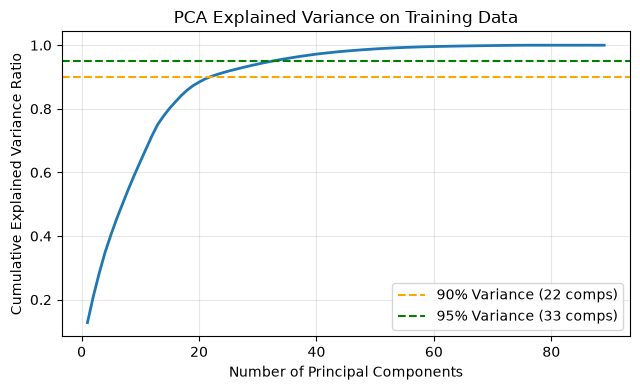

In [ ]:
#PCA Training set only
X_train_encoded = clone(preprocess).fit_transform(X_train)
pca_explorer = PCA(random_state=RANDOM_STATE).fit(X_train_encoded) #Fit PCA explorer with all 89 columns (so ordered from most to least variance)
cum_var = np.cumsum(pca_explorer.explained_variance_ratio_) #explained_variance_ratio_ is the share of total variance each component captures. The cumulative sum ends at 1.0

n_80 = np.argmax(cum_var >= 0.80) + 1 #for cum_var greater than 80%
n_90 = np.argmax(cum_var >= 0.90) + 1
n_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Total encoded features: {X_train_encoded.shape[1]}")
print(f"Components for 80% variance: {n_80} | 90% variance: {n_90} | 95% variance: {n_95}")

#Plotting the components against the cumulative varaince 
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(range(1, len(cum_var) + 1), cum_var, linewidth=2)
ax.axhline(0.90, color="orange", linestyle="--", label=f"90% Variance ({n_90} comps)")
ax.axhline(0.95, color="green", linestyle="--", label=f"95% Variance ({n_95} comps)")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance Ratio")
ax.set_title("PCA Explained Variance on Training Data")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

=== PCA + LR (Baseline) ===
Train Accuracy: 0.7552 | Test Accuracy: 0.7540
              precision    recall  f1-score   support

Not canceled       0.78      0.91      0.84      6929
    Canceled       0.63      0.39      0.48      2869

    accuracy                           0.75      9798
   macro avg       0.71      0.65      0.66      9798
weighted avg       0.74      0.75      0.73      9798



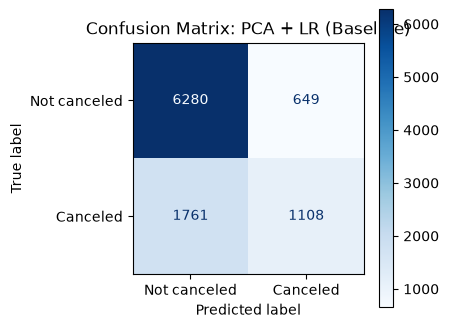

Best PCA + LR Params: {'clf__C': 10.0, 'clf__class_weight': 'balanced', 'pca__n_components': 0.95}
Best CV F1: 0.5919

=== PCA + LR (Tuned) ===
Train Accuracy: 0.7061 | Test Accuracy: 0.6996
              precision    recall  f1-score   support

Not canceled       0.85      0.70      0.77      6929
    Canceled       0.49      0.70      0.58      2869

    accuracy                           0.70      9798
   macro avg       0.67      0.70      0.67      9798
weighted avg       0.74      0.70      0.71      9798



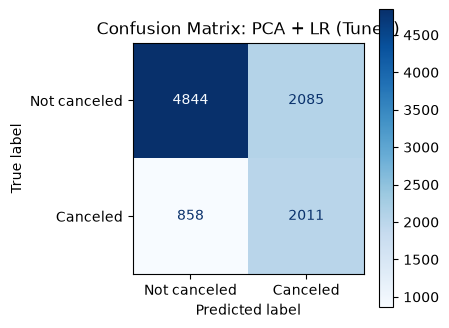

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['LeadTime','ArrivalDateYear','ArrivalDateMonth',...,'ADR', 'TotalOfSpecialRequests','HasCompany']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [ ]:
#PCA + Baseline and Tuned Logistic Regression

#Baseline Logistic Regression on PCA-reduced features (retaining 95% variance)
model_pca_base = Pipeline([
    ("prep", clone(preprocess)),
    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

evaluate_classifier("PCA + LR (Baseline)", model_pca_base, X_train, y_train, X_test, y_test, cv)

#Hyperparameter-Tuned Logistic Regression + PCA Dimensionality Tuning
pca_tune_pipe = Pipeline([
    ("prep", clone(preprocess)),
    ("pca", PCA(random_state=RANDOM_STATE)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

param_grid_pca = {
    "pca__n_components": [15, 25, 0.90, 0.95],
    "clf__C": [0.01, 0.1, 1.0, 10.0],
    "clf__class_weight": [None, "balanced"],
}

grid_pca = GridSearchCV(
    estimator=pca_tune_pipe,
    param_grid=param_grid_pca,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

grid_pca.fit(X_train, y_train)
print("Best PCA + LR Params:", grid_pca.best_params_)
print(f"Best CV F1: {grid_pca.best_score_:.4f}\n")

model_pca_tuned = grid_pca.best_estimator_
evaluate_classifier("PCA + LR (Tuned)", model_pca_tuned, X_train, y_train, X_test, y_test, cv)

=== LDA + LR (Baseline) ===
Train Accuracy: 0.7662 | Test Accuracy: 0.7609
              precision    recall  f1-score   support

Not canceled       0.79      0.91      0.84      6929
    Canceled       0.64      0.41      0.50      2869

    accuracy                           0.76      9798
   macro avg       0.72      0.66      0.67      9798
weighted avg       0.75      0.76      0.74      9798



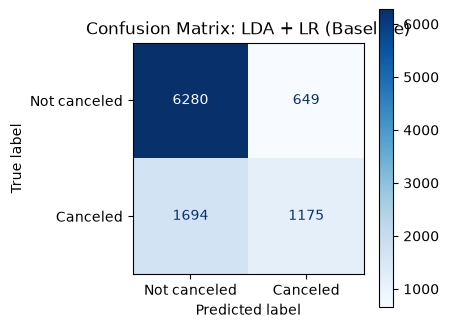

Best LDA + LR Params: {'clf__C': 0.01, 'clf__class_weight': 'balanced', 'lda__shrinkage': None, 'lda__solver': 'svd'}
Best CV F1: 0.6015

=== LDA + LR (Tuned) ===
Train Accuracy: 0.7212 | Test Accuracy: 0.7179
              precision    recall  f1-score   support

Not canceled       0.86      0.72      0.78      6929
    Canceled       0.51      0.71      0.60      2869

    accuracy                           0.72      9798
   macro avg       0.69      0.72      0.69      9798
weighted avg       0.76      0.72      0.73      9798



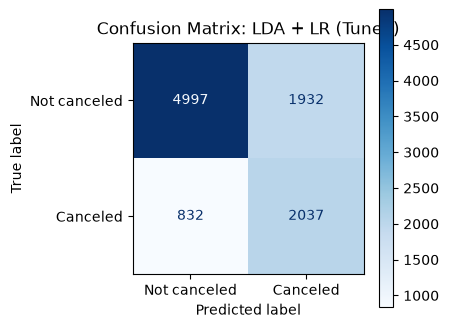

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('lda', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['LeadTime','ArrivalDateYear','ArrivalDateMonth',...,'ADR', 'TotalOfSpecialRequests','HasCompany']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [11]:
#LDA + Baseline and Tuned Logistic Regression

# 1. Baseline Logistic Regression on 1D LDA Projection
model_lda_base = Pipeline([
    ("prep", clone(preprocess)),
    ("lda", LinearDiscriminantAnalysis(n_components=1, solver="svd")),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

evaluate_classifier("LDA + LR (Baseline)", model_lda_base, X_train, y_train, X_test, y_test, cv)

# 2. Hyperparameter-Tuned Logistic Regression + LDA Shrinkage Tuning
lda_tune_pipe = Pipeline([
    ("prep", clone(preprocess)),
    ("lda", LinearDiscriminantAnalysis(n_components=1)),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

param_grid_lda = [
    {
        "lda__solver": ["svd"],
        "lda__shrinkage": [None],
        "clf__C": [0.01, 0.1, 1.0, 10.0],
        "clf__class_weight": [None, "balanced"],
    },
    {
        "lda__solver": ["eigen"],
        "lda__shrinkage": ["auto", 0.1, 0.5],
        "clf__C": [0.01, 0.1, 1.0, 10.0],
        "clf__class_weight": [None, "balanced"],
    },
]

grid_lda = GridSearchCV(
    estimator=lda_tune_pipe,
    param_grid=param_grid_lda,
    scoring="f1",
    cv=cv,
    n_jobs=-2,
    refit=True,
)

grid_lda.fit(X_train, y_train)
print("Best LDA + LR Params:", grid_lda.best_params_)
print(f"Best CV F1: {grid_lda.best_score_:.4f}\n")

model_lda_tuned = grid_lda.best_estimator_
evaluate_classifier("LDA + LR (Tuned)", model_lda_tuned, X_train, y_train, X_test, y_test, cv)

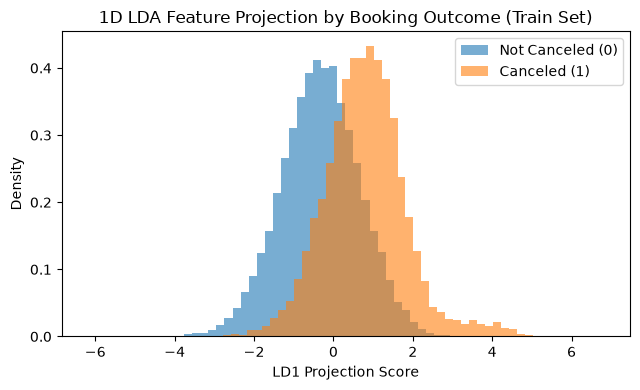

In [12]:
#Visualize LDA Class seperation

# Inspect how well the single LDA discriminant separates Canceled vs. Not Canceled
lda_step = model_lda_tuned[:-1]
Z_train_lda = lda_step.transform(X_train).ravel()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(Z_train_lda[y_train == 0], bins=50, alpha=0.6, density=True, label="Not Canceled (0)")
ax.hist(Z_train_lda[y_train == 1], bins=50, alpha=0.6, density=True, label="Canceled (1)")
ax.set_xlabel("LD1 Projection Score")
ax.set_ylabel("Density")
ax.set_title("1D LDA Feature Projection by Booking Outcome (Train Set)")
ax.legend()
plt.tight_layout()
plt.show()

,Model,CV Accuracy,CV F1,CV ROC-AUC,Train Acc,Test Acc,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,LR (Baseline),0.7672 ± 0.0016,0.5160 ± 0.0057,0.7959 ± 0.0023,0.7687,0.7596,0.6397,0.4102,0.4999,0.7890,0.6154
1,LR (Tuned),0.7192 ± 0.0041,0.6077 ± 0.0035,0.7967 ± 0.0023,0.7215,0.7163,0.5110,0.7226,0.5986,0.7898,0.6085
2,PCA + LR (Baseline),0.7554 ± 0.0013,0.4809 ± 0.0040,0.7772 ± 0.0021,0.7552,0.7540,0.6306,0.3862,0.4790,0.7730,0.5819
3,PCA + LR (Tuned),0.7056 ± 0.0050,0.5919 ± 0.0043,0.7779 ± 0.0024,0.7061,0.6996,0.4910,0.7009,0.5775,0.7738,0.5757
4,LDA + LR (Baseline),0.7658 ± 0.0014,0.5127 ± 0.0057,0.7917 ± 0.0015,0.7662,0.7609,0.6442,0.4096,0.5007,0.7860,0.6138
5,LDA + LR (Tuned),0.7193 ± 0.0049,0.6015 ± 0.0052,0.7917 ± 0.0015,0.7212,0.7179,0.5132,0.7100,0.5958,0.7860,0.6138
6,LDA + LR (Baseline),0.7658 ± 0.0014,0.5127 ± 0.0057,0.7917 ± 0.0015,0.7662,0.7609,0.6442,0.4096,0.5007,0.7860,0.6138
7,LDA + LR (Tuned),0.7193 ± 0.0049,0.6015 ± 0.0052,0.7917 ± 0.0015,0.7212,0.7179,0.5132,0.7100,0.5958,0.7860,0.6138


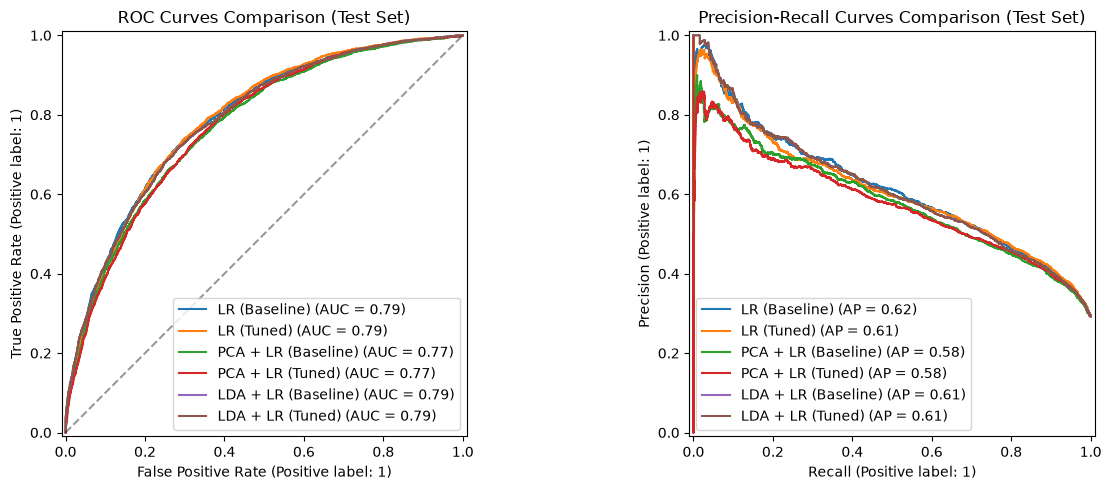

In [13]:
#Overall Comparison
summary_df = pd.DataFrame(results_log)
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, est in fitted_models.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(est, X_test, y_test, ax=axes[1], name=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC Curves Comparison (Test Set)")
axes[1].set_title("Precision-Recall Curves Comparison (Test Set)")
plt.tight_layout()
plt.show()